## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу:
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования:

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже)

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

#### Загрузим данные о лауреатах из файла laureates.json

In [1]:
import json

with open('laureates.json', 'r', encoding='utf-8') as file:
    laureates = json.load(file)

#### Проверим, сколько лауреатов в датасете

In [2]:
len(laureates['laureates'])

1028

#### Проверим обработку вложенного словаря на примере конфига премии

In [3]:
from json_dict_processing import process_dictionary_with_config
from prizes_configs import CONFIG_PRIZE

test_data = {
    'category': {
        'en': 'Physics'
    }
}

result = process_dictionary_with_config(test_data, CONFIG_PRIZE)

assert result['category_en'] == 'Physics'
assert result['prize_amount'] is None


#### Применим функции к датасету, для каждого лауреата определим его тип и сформируем словарь с характеристиками

In [4]:
from laureates_configs import process_orgs, process_persons

def get_laureate_data(laureate):
    """
    Определите тип лауреата and соотв образом обработайте данных.

    Args:
        laureate: Dictionary with laureate data

    Returns:
        Processed laureate data with added 'type_' field ('person' or 'org')

    Determines type by:
    - 'knownName' key → person (uses process_persons)
    - 'orgName' key → org (uses process_orgs)
    """

    if 'knownName' in laureate:
        result = process_persons(laureate)
        result['type_'] = 'person'

    elif 'orgName' in laureate:
        result = process_orgs(laureate)
        result['type_'] = 'org'

    return result


laureates_data = []

for laureate in laureates['laureates']:
    laureates_data.append(get_laureate_data(laureate))

#### Проверим корректность обработанных данных (количество записей, наличие обязательных полей и определение типов лауреатов)

In [5]:
assert len(laureates_data) == len(laureates['laureates'])

for laureate in laureates_data:
    assert laureate['type_'] in ['person', 'org']
    assert laureate['id'] is not None
    assert laureate['name'] is not None
    assert isinstance(laureate['prizes_relevant'], list)

    for prize in laureate['prizes_relevant']:
        assert isinstance(prize['award_year'], int)



### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один?

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

## Технический анализ данных

#### Начнем EDA с определения общего количества лауреатов в обработанном датасете:

In [6]:
print('Всего лауреатов:', len(laureates_data))

Всего лауреатов: 1028


#### Разделим лауреатов на людей и организации:

In [7]:
persons = []
orgs = []

for laureate in laureates_data:
    if laureate['type_'] == 'person':
        persons.append(laureate)
    else:
        orgs.append(laureate)

print('Людей:', len(persons))
print('Организаций:', len(orgs))

Людей: 1000
Организаций: 28


#### Подключим вспомогательные функции из файла `dataset_helpers.py` для группировки данных, подсчёта пропусков и определения десятилетия.


#### Проверим полноту данных о людях и организациях (посчитаем количество и долю пропущенных значений):

In [8]:
from dataset_helpers import count_missing

person_fields = list(persons[0].keys())
org_fields = list(orgs[0].keys())

person_missing, person_share = count_missing(persons, person_fields)
org_missing, org_share = count_missing(orgs, org_fields)

print('Пропуски у людей:', person_missing)
print('Доля пропусков у людей, %:', person_share)

print('Пропуски у организаций:', org_missing)
print('Доля пропусков у организаций, %:', org_share)

Пропуски у людей: {'id': 0, 'name': 0, 'gender': 0, 'birth_year': 0, 'country_birth': 3, 'country_now': 3, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков у людей, %: {'id': 0.0, 'name': 0.0, 'gender': 0.0, 'birth_year': 0.0, 'country_birth': 0.3, 'country_now': 0.3, 'prizes_relevant': 0.0, 'type_': 0.0}
Пропуски у организаций: {'id': 0, 'name': 0, 'founded_year': 1, 'country_founded': 4, 'country_now': 4, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков у организаций, %: {'id': 0.0, 'name': 0.0, 'founded_year': 3.57, 'country_founded': 14.29, 'country_now': 14.29, 'prizes_relevant': 0.0, 'type_': 0.0}


#### Проанализируем id лауреатов (найдем минимальный и максимальный id, проверим на повторы и пропуски в последовательности):

In [9]:
ids = []

for laureate in laureates_data:
    ids.append(int(laureate['id']))

print('Минимальный id:', min(ids))
print('Максимальный id:', max(ids))

for laureate in laureates_data:
    if int(laureate['id']) == min(ids):
        print('Годы награждения лауреата с минимальным id:',
              [prize['award_year'] for prize in laureate['prizes_relevant']])

    if int(laureate['id']) == max(ids):
        print('Годы награждения лауреата с максимальным id:',
              [prize['award_year'] for prize in laureate['prizes_relevant']])

print('Повторяющихся id:', len(ids) - len(set(ids)))

sorted_ids = sorted(ids)
id_gaps = []

for i in range(len(sorted_ids) - 1):
    if sorted_ids[i + 1] - sorted_ids[i] > 1:
        id_gaps.append((sorted_ids[i], sorted_ids[i + 1]))

print('Количество разрывов между id:', len(id_gaps))
print('Пары id с разницей больше 1:', id_gaps)


Минимальный id: 1
Максимальный id: 1070
Годы награждения лауреата с максимальным id: [2026]
Годы награждения лауреата с минимальным id: [1901]
Повторяющихся id: 0
Количество разрывов между id: 24
Пары id с разницей больше 1: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789), (858, 861), (896, 903), (949, 958), (1009, 1011)]


## Выводы технического анализа

В датасете содержится 1 028 лауреатов (1 000 человек и 28 организаций)

Пропуски встречаются в информации о странах рождения людей и их современном территориальном соответствии (0,3%), о годе основания организаций (3,57%) и странах основания организаций (14,29%)

Минимальный id равен 1 (премия 1901 года), максимальный id равен 1070 (премия 2026 года)

Повторяющихся id нет, но у 24 пар соседних id разница больше 1

## Задание
Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by.

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты?

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз?
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

#### Подключим функции из файла `aggregations.py` для расчёта статистики, подсчета элементов и поиска наиболее частых значений


#### Определим страны с наибольшим количеством лауреатов, для этого исключим записи без информации о стране, сгруппируем данные и найдем пять лидирующих стран (пропуски можно было бы заполнить модой, но не будем этого делать, чтобы не увеличить искусственно количество лауреатов из наиболее популярной страны)

*Использовались данные о странах рождения лауреатов и основания организаций с учетом современных границ государств

In [10]:
from dataset_helpers import group_by_attributes, get_decade
from aggregations import aggregate, count_items, top_n

laureates_with_country = []

for laureate in laureates_data:
    if laureate['country_now'] is not None:
        laureates_with_country.append(laureate)

countries = group_by_attributes(laureates_with_country, ['country_now'])

country_counts = {}

for country, laureates_list in countries.items():
    country_counts[country[0]] = len(laureates_list)

top_countries = top_n(country_counts, 5)

print('Топ-5 стран по количеству лауреатов:')

for i, (country, count) in enumerate(top_countries, 1):
    print(f'{i}. {country}: {count}')

Топ-5 стран по количеству лауреатов:
1. USA: 306
2. United Kingdom: 96
3. Germany: 86
4. France: 66
5. Japan: 32


#### Визуализируем с помощью столбчатой диаграммы

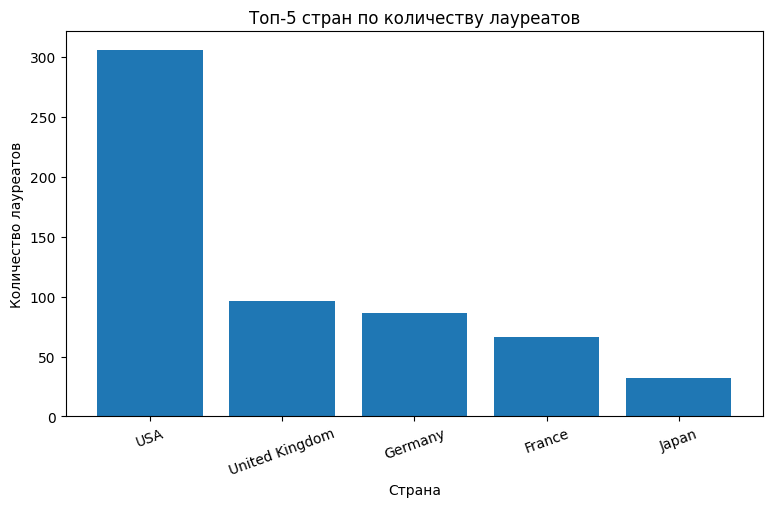

In [11]:
import matplotlib.pyplot as plt

countries = []
counts = []

for country, count in top_countries:
    countries.append(country)
    counts.append(count)

plt.figure(figsize=(9, 5))
plt.bar(countries, counts)

plt.title('Топ-5 стран по количеству лауреатов')
plt.xlabel('Страна')
plt.ylabel('Количество лауреатов')
plt.xticks(rotation=20)
plt.show()

#### Вывод
Видим, что наибольшее количество Нобелевских лауреатов приходится на США (306),Великобританию (96), Германию (86), Францию (66) и Японию (32), при том в США количество лауреатов более чем в три раза превышает количество лауреатов в Великобритании

#### Подготовим данные для сравнения стран по категориям премии
*Будем учитывать каждого лауреата только один раз в рамках одной категории

In [12]:
countries_by_category = []

for laureate in laureates_with_country:
    categories = set()

    for prize in laureate['prizes_relevant']:
        categories.add(prize['category_en'])

    for category in categories:
        countries_by_category.append({
            'country': laureate['country_now'],
            'category': category
        })

#### Для каждой категории определим страны с наибольшим количеством лауреатов и сравним рейтинги

In [13]:
grouped_data = group_by_attributes(countries_by_category, ['category'])

for category, laureates_list in sorted(grouped_data.items()):
    countries = group_by_attributes(laureates_list, ['country'])

    country_counts = {}

    for country, country_laureates in countries.items():
        country_counts[country[0]] = len(country_laureates)

    print(f'\n{category[0]}:')

    for i, (country, count) in enumerate(top_n(country_counts, 5), 1):
        print(f'{i}. {country}: {count}')


Chemistry:
1. USA: 59
2. Germany: 26
3. United Kingdom: 26
4. France: 12
5. Japan: 9

Economic Sciences:
1. USA: 56
2. United Kingdom: 7
3. Canada: 5
4. France: 5
5. the Netherlands: 4

Literature:
1. France: 12
2. USA: 10
3. Sweden: 7
4. Poland: 7
5. Germany: 7

Peace:
1. USA: 26
2. France: 12
3. Switzerland: 8
4. United Kingdom: 7
5. Russia: 5

Physics:
1. USA: 71
2. Germany: 27
3. United Kingdom: 25
4. France: 13
5. Japan: 12

Physiology or Medicine:
1. USA: 85
2. United Kingdom: 25
3. Germany: 20
4. France: 12
5. Sweden: 8


#### Вывод

США лидируют по количеству лауреатов в пяти из шести категорий (химия, экономика, мир, физика и медицина), и только в литературе США на втором месте, посколько первое занимает Франция (из США 10 лауретов по литературе, а из Франции 12)

Наибольшее количество лауреатов из США приходится на медицину (85 лауреатов) и физику (71 лауреат)

#### Теперь посмотрим, как менялось количество лауреатов из пяти ведущих стран по десятилетиям
*Исключим повторное появление одного лауреата в одном десятилетии

In [14]:
countries_by_decade = []
seen = set()

for laureate in laureates_with_country:
    if laureate['country_now'] in dict(top_countries):

        for prize in laureate['prizes_relevant']:
            decade = get_decade(prize['award_year'])
            key = (laureate['id'], decade)

            if key not in seen:
                seen.add(key)

                countries_by_decade.append({
                    'country': laureate['country_now'],
                    'decade': decade
                })

#### Сгруппируем по странам и десятилетиям и посчитаем количество лауреатов в каждой группе

In [15]:
grouped_decades = group_by_attributes(
    countries_by_decade, ['decade', 'country']
)

decade_counts = {}

for key, laureates_list in grouped_decades.items():
    decade_counts[key] = len(laureates_list)

print('Количество лауреатов по десятилетиям:')

for decade in range(1900, 2030, 10):
    print(f'\n{decade}-е годы:')

    for country, count in top_countries:
        print(f'{country}: {decade_counts.get((decade, country), 0)}')

Количество лауреатов по десятилетиям:

1900-е годы:
USA: 1
United Kingdom: 3
Germany: 8
France: 9
Japan: 0

1910-е годы:
USA: 3
United Kingdom: 2
Germany: 6
France: 6
Japan: 0

1920-е годы:
USA: 4
United Kingdom: 7
Germany: 10
France: 8
Japan: 0

1930-е годы:
USA: 14
United Kingdom: 10
Germany: 8
France: 3
Japan: 0

1940-е годы:
USA: 14
United Kingdom: 4
Germany: 3
France: 1
Japan: 1

1950-е годы:
USA: 21
United Kingdom: 10
Germany: 6
France: 4
Japan: 0

1960-е годы:
USA: 22
United Kingdom: 7
Germany: 7
France: 8
Japan: 2

1970-е годы:
USA: 33
United Kingdom: 14
Germany: 8
France: 4
Japan: 2

1980-е годы:
USA: 33
United Kingdom: 5
Germany: 11
France: 4
Japan: 2

1990-е годы:
USA: 43
United Kingdom: 6
Germany: 4
France: 2
Japan: 1

2000-е годы:
USA: 54
United Kingdom: 10
Germany: 6
France: 4
Japan: 8

2010-е годы:
USA: 39
United Kingdom: 11
Germany: 4
France: 5
Japan: 11

2020-е годы:
USA: 28
United Kingdom: 8
Germany: 5
France: 8
Japan: 5


#### Для более простого восприятия информации построим линейный график, чтобы увидеть динамику количества лауреатов из разных стран и проследить изменение лидерства во времени

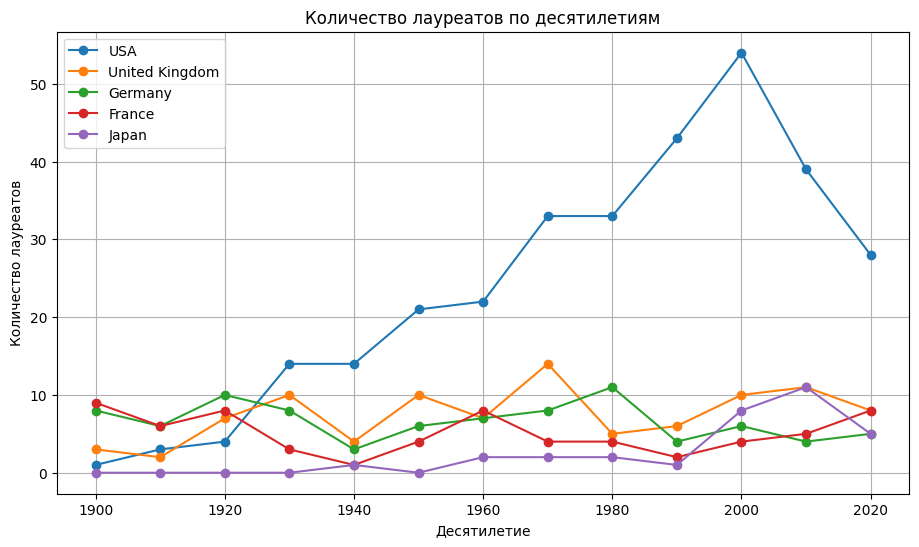

In [16]:
plt.figure(figsize=(11, 6))

decades = list(range(1900, 2030, 10))

for country, count in top_countries:
    values = []

    for decade in decades:
        values.append(decade_counts.get((decade, country), 0))

    plt.plot(decades, values, marker='o', label=country)

plt.title('Количество лауреатов по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Количество лауреатов')
plt.legend()
plt.grid(True)
plt.show()

#### Вывод

В начале 20 века выделялись Германия и Франция, но со временем лидерство перешло к США

Количество лауреатов из США росло на протяжении большей части 20 века и достигло максимума в 2000-х годах (54 лауреата)

*Данные за 2020-е пока неполные, поэтому сравнивать их с предыдущими десятилетиями некорректно

#### Поскольку большинство лауреатов - люди, сосредоточимся на этой группе и перейдем к анализу социально-демографических характеристик лауреатов
#### Рассчитаем примерный возраст лауреатов на момент получения первой Нобелевской премии как разницу между годом самого раннего награждения лауреата и его годом рождения


In [17]:
persons_age = []

for laureate in persons:
    if laureate['birth_year'] is not None:
        first_prize = min(
            laureate['prizes_relevant'],
            key=lambda prize: prize['award_year']
        )

        age = first_prize['award_year'] - laureate['birth_year']

        persons_age.append({
            'name': laureate['name'],
            'age': age,
            'category': first_prize['category_en'],
            'award_year': first_prize['award_year']
        })

#### Рассчитаем основные статистические показатели возраста (среднее значение, медиану, максимум и минимум)

In [18]:
import statistics

print(f'Количество лауреатов: {count_items(persons_age)}')
print(f'Средний возраст: {aggregate(persons_age, "age", statistics.mean):.1f}')
print(f'Медианный возраст: {aggregate(persons_age, "age", statistics.median):.1f}')
print(f'Максимальный возраст: {aggregate(persons_age, "age", max)}')
print(f'Минимальный возраст: {aggregate(persons_age, "age", min)}')

Количество лауреатов: 1000
Средний возраст: 60.6
Медианный возраст: 61.0
Максимальный возраст: 97
Минимальный возраст: 17


#### Сравним средний и медианный возраст получения первой премии в разных категориях, чтобы выяснить, в каких областях лауреатов в основном награждают раньше или позже

In [19]:
age_groups = group_by_attributes(persons_age, ['category'])

print('Возраст получения первой премии по категориям:')

for category, laureates_list in sorted(age_groups.items()):
    mean_age = aggregate(laureates_list, 'age', statistics.mean)
    median_age = aggregate(laureates_list, 'age', statistics.median)

    print(f'{category[0]}: средний {mean_age:.1f}, медианный {median_age:.1f}')

Возраст получения первой премии по категориям:
Chemistry: средний 59.4, медианный 58.0
Economic Sciences: средний 67.2, медианный 67.0
Literature: средний 65.0, медианный 67.0
Peace: средний 61.0, медианный 62.0
Physics: средний 57.8, медианный 56.0
Physiology or Medicine: средний 59.0, медианный 58.0


#### Построим столбчатую диаграмму среднего возраста по категориям

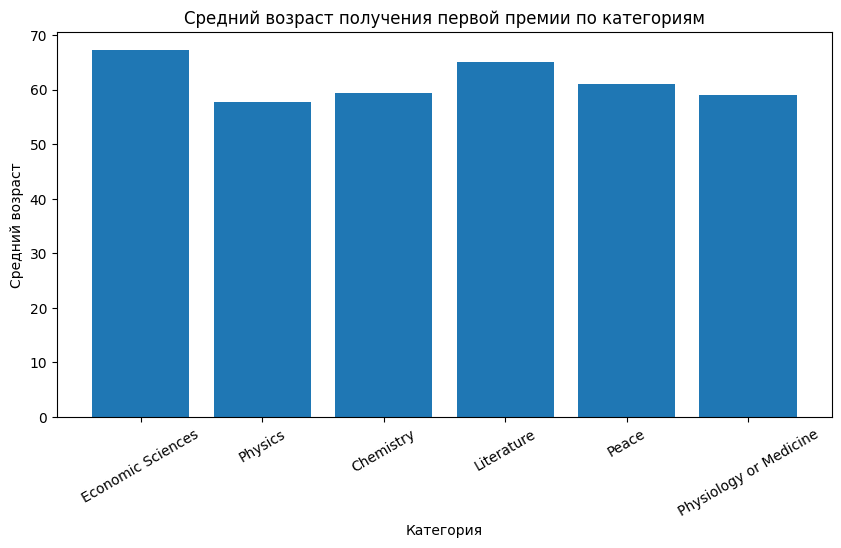

In [20]:
categories = []
mean_ages = []

for category, laureates_list in age_groups.items():
    categories.append(category[0])
    mean_ages.append(
        aggregate(laureates_list, 'age', statistics.mean)
    )

plt.figure(figsize=(10, 5))
plt.bar(categories, mean_ages)

plt.title('Средний возраст получения первой премии по категориям')
plt.xlabel('Категория')
plt.ylabel('Средний возраст')
plt.xticks(rotation=30)
plt.show()

#### Рассчитаем средний возраст получения первой премии по десятилетиям, чтобы понять, как менялся возраст лауреатов в истории

In [21]:
for person in persons_age:
    person['decade'] = get_decade(person['award_year'])

age_by_decade = group_by_attributes(persons_age, ['decade'])

decades = []
mean_ages_by_decade = []

for decade, laureates_list in sorted(age_by_decade.items()):
    decades.append(decade[0])
    mean_ages_by_decade.append(
        aggregate(laureates_list, 'age', statistics.mean)
    )

print('Средний возраст получения первой премии по десятилетиям:')

for decade, mean_age in zip(decades, mean_ages_by_decade):
    print(f'{decade}-е: {mean_age:.1f} лет')

Средний возраст получения первой премии по десятилетиям:
1900-е: 57.8 лет
1910-е: 53.1 лет
1920-е: 55.0 лет
1930-е: 51.6 лет
1940-е: 58.0 лет
1950-е: 54.3 лет
1960-е: 56.4 лет
1970-е: 59.3 лет
1980-е: 60.5 лет
1990-е: 62.1 лет
2000-е: 65.9 лет
2010-е: 66.9 лет
2020-е: 69.4 лет


#### Визуализируем динамику среднего возраста с помощью линейного графика

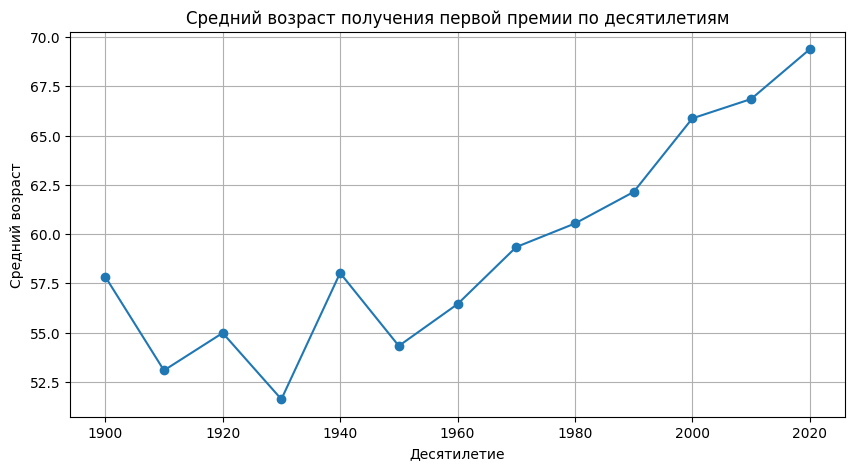

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(decades, mean_ages_by_decade, marker='o')

plt.title('Средний возраст получения первой премии по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Средний возраст')
plt.grid(True)
plt.show()

#### Вывод

Средний возраст получения первой Нобелевской премии составляет 60,6 года, медианный - 61 год, они практически совпадают

Минимальный возраст получения первой Нобелевской премии составляет 17 лет, а максимальный — 97 лет

Самый высокий средний возраст в категории "Экономика" (67,2 года), а самый низкий - в категории "Физика" (57,8 года), разница между ними 9,4 года

Можем заметить увеличение среднего возраста первого награждения со временем, поскольку в 1930-х средний возраст первого награждения составлял 51,6 года, в 2010-х - 66,9 года, а 2020-х составляет 69,4 года (но десятилетие еще не закончилось)

#### Определим количество и долю мужчин и женщин среди лауреатов-людей

In [23]:
gender_groups = group_by_attributes(persons, ['gender'])

print('Гендерное распределение лауреатов:')

for gender, laureates_list in gender_groups.items():
    count = len(laureates_list)
    share = count / len(persons) * 100

    print(f'{gender[0]}: {count} ({share:.1f}%)')

Гендерное распределение лауреатов:
male: 931 (93.1%)
female: 69 (6.9%)


#### Подготовим данные для анализа гендерного распределения по категориям и десятилетиям
*Для каждого человека будем учитывать категорию и год его первой премии

In [24]:
gender_data = []

for laureate in persons:
    first_prize = min(
        laureate['prizes_relevant'],
        key=lambda prize: prize['award_year']
    )

    gender_data.append({
        'gender': laureate['gender'],
        'category': first_prize['category_en'],
        'decade': get_decade(first_prize['award_year'])
    })

#### Посчитаем количество и долю женщин в каждой категории Нобелевской премии

In [25]:
category_groups = group_by_attributes(gender_data, ['category'])

print('Количество женщин по категориям:')

for category, laureates_list in sorted(category_groups.items()):
    women_count = 0

    for laureate in laureates_list:
        if laureate['gender'] == 'female':
            women_count += 1

    share = women_count / len(laureates_list) * 100

    print(f'{category[0]}: {women_count} ({share:.1f}%)')

Количество женщин по категориям:
Chemistry: 7 (3.5%)
Economic Sciences: 3 (3.0%)
Literature: 19 (15.4%)
Peace: 21 (18.8%)
Physics: 5 (2.2%)
Physiology or Medicine: 14 (6.0%)


#### Посмотрим, как менялось количество и доля женщин среди лауреатов по десятилетиям

In [26]:
decade_groups = group_by_attributes(gender_data, ['decade'])

decades = []
women_counts = []
women_shares = []

print('Женщины-лауреаты по десятилетиям:')

for decade, laureates_list in sorted(decade_groups.items()):
    women_count = 0

    for laureate in laureates_list:
        if laureate['gender'] == 'female':
            women_count += 1

    share = women_count / len(laureates_list) * 100

    decades.append(decade[0])
    women_counts.append(women_count)
    women_shares.append(share)

    print(f'{decade[0]}-е: {women_count} ({share:.1f}%)')

Женщины-лауреаты по десятилетиям:
1900-е: 3 (5.4%)
1910-е: 0 (0.0%)
1920-е: 2 (3.7%)
1930-е: 3 (5.5%)
1940-е: 3 (7.5%)
1950-е: 0 (0.0%)
1960-е: 3 (4.1%)
1970-е: 4 (3.9%)
1980-е: 4 (4.3%)
1990-е: 7 (6.9%)
2000-е: 11 (9.2%)
2010-е: 13 (11.1%)
2020-е: 16 (19.8%)


#### Построим линейный график изменения доли женщин среди лауреатов

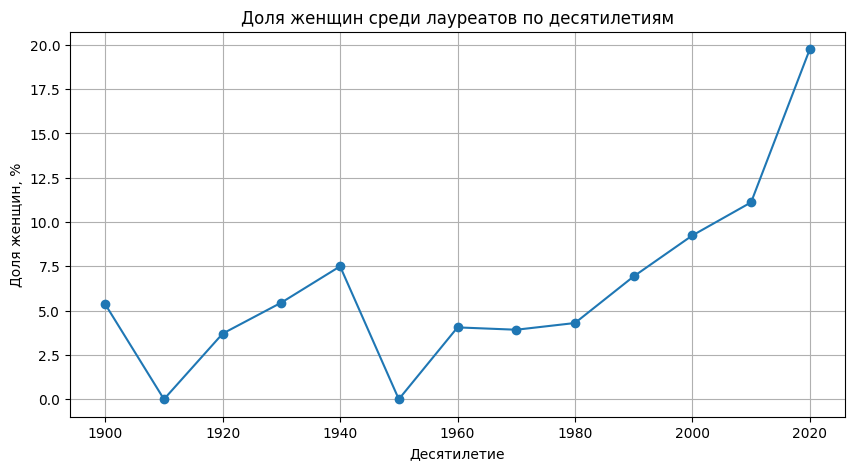

In [27]:
plt.figure(figsize=(10, 5))
plt.plot(decades, women_shares, marker='o')

plt.title('Доля женщин среди лауреатов по десятилетиям')
plt.xlabel('Десятилетие')
plt.ylabel('Доля женщин, %')
plt.grid(True)
plt.show()

#### Сравним количество женщин в разных категориях по десятилетиям

In [28]:
category_decade_groups = group_by_attributes(
    gender_data, ['decade', 'category']
)

print('Количество женщин по категориям и десятилетиям:')

for decade in decades:
    print(f'\n{decade}-е:')

    for key, laureates_list in sorted(category_decade_groups.items()):
        if key[0] == decade:
            women_count = 0

            for laureate in laureates_list:
                if laureate['gender'] == 'female':
                    women_count += 1

            print(f'{key[1]}: {women_count}')

Количество женщин по категориям и десятилетиям:

1900-е:
Chemistry: 0
Literature: 1
Peace: 1
Physics: 1
Physiology or Medicine: 0

1910-е:
Chemistry: 0
Literature: 0
Peace: 0
Physics: 0
Physiology or Medicine: 0

1920-е:
Chemistry: 0
Literature: 2
Peace: 0
Physics: 0
Physiology or Medicine: 0

1930-е:
Chemistry: 1
Literature: 1
Peace: 1
Physics: 0
Physiology or Medicine: 0

1940-е:
Chemistry: 0
Literature: 1
Peace: 1
Physics: 0
Physiology or Medicine: 1

1950-е:
Chemistry: 0
Literature: 0
Peace: 0
Physics: 0
Physiology or Medicine: 0

1960-е:
Chemistry: 1
Economic Sciences: 0
Literature: 1
Peace: 0
Physics: 1
Physiology or Medicine: 0

1970-е:
Chemistry: 0
Economic Sciences: 0
Literature: 0
Peace: 3
Physics: 0
Physiology or Medicine: 1

1980-е:
Chemistry: 0
Economic Sciences: 0
Literature: 0
Peace: 1
Physics: 0
Physiology or Medicine: 3

1990-е:
Chemistry: 0
Economic Sciences: 0
Literature: 3
Peace: 3
Physics: 0
Physiology or Medicine: 1

2000-е:
Chemistry: 1
Economic Sciences: 1
Liter

#### Вывод

Среди 1 000 лауреатов-людей 69 женщин (6,9%) и 931 мужчина (93,1%)

Наибольшее количество женщин получило первую премию в категориях «Мир» (21) и «Литература» (19), наименьшее - в категориях "Экономика" (3) и "Физика" (5)

С 1990-х наблюдается рост доли женщин среди лауреатов, то есть доля росла с 6,9% в 1990-х до 11,1% в 2010-х, а в 2020-х доля достигает 19,8% (но десятилетие еще не закончилось)

В последние десятилетия больше всего женщин награждали в категориях "Мир", "Литература" и "Медицина"

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)

#### Соберем тексты мотиваций вручения Нобелевских премий в список

In [29]:
motivations = []

for laureate in laureates_data:
    for prize in laureate['prizes_relevant']:
        if prize['motivation_en'] is not None:
            motivations.append(prize['motivation_en'])

print(f'Количество текстов мотиваций: {len(motivations)}')

Количество текстов мотиваций: 1036


#### Подготовим тексты к анализу (приведем к нижнему регистру, удалим знаки препинания и разобьем на слова)


In [30]:
from dataset_helpers import split_into_words

words = []

for motivation in motivations:
    words.extend(split_into_words(motivation))

print(f'Всего слов: {len(words)}')
print(words[:20])


Всего слов: 15281
['for', 'their', 'analyses', 'of', 'markets', 'with', 'asymmetric', 'information', 'for', 'the', 'discovery', 'of', 'the', 'connection', 'between', 'collective', 'motion', 'and', 'particle', 'motion']


#### Подсчитаем частоту каждого слова и выделим 50 наиболее распространенных

In [31]:
from aggregations import count_words

word_counts = count_words(words)
top_words = top_n(word_counts, 50)

print('Топ-50 самых частых слов:')

for i, (word, count) in enumerate(top_words, 1):
    print(f'{i}. {word}: {count}')

Топ-50 самых частых слов:
1. of: 1291
2. the: 1245
3. for: 1149
4. and: 670
5. in: 449
6. their: 394
7. his: 376
8. to: 278
9. discovery: 211
10. discoveries: 172
11. a: 150
12. concerning: 124
13. development: 110
14. work: 106
15. on: 101
16. with: 99
17. which: 99
18. by: 82
19. theory: 74
20. contributions: 61
21. has: 60
22. structure: 58
23. that: 54
24. peace: 53
25. recognition: 48
26. economic: 45
27. human: 44
28. chemical: 43
29. as: 42
30. analysis: 42
31. new: 41
32. its: 39
33. synthesis: 38
34. pioneering: 38
35. an: 38
36. fundamental: 37
37. efforts: 36
38. between: 34
39. chemistry: 34
40. he: 34
41. her: 32
42. studies: 31
43. through: 31
44. international: 30
45. method: 30
46. especially: 29
47. methods: 29
48. having: 28
49. role: 27
50. research: 26


#### Для фильтрации текстов используем файл `stopwords.py` со списком служебных и общеупотребительных слов
*После удаления стоп-слов повторно снова анализируем результаты и дополняем список служебными и общеупотребительными словами


#### Удалим стоп-слова из текстов и снова определим топ-50

In [32]:
from stopwords import STOPWORDS

filtered_words = []

for word in words:
    if word not in STOPWORDS:
        filtered_words.append(word)

filtered_counts = count_words(filtered_words)
top_filtered = top_n(filtered_counts, 50)

print('Топ-50 слов после удаления стоп-слов:')

for i, (word, count) in enumerate(top_filtered, 1):
    print(f'{i}. {word}: {count}')

Топ-50 слов после удаления стоп-слов:
1. discovery: 211
2. discoveries: 172
3. development: 110
4. work: 106
5. theory: 74
6. contributions: 61
7. structure: 58
8. peace: 53
9. recognition: 48
10. economic: 45
11. human: 44
12. chemical: 43
13. analysis: 42
14. new: 41
15. synthesis: 38
16. pioneering: 38
17. fundamental: 37
18. efforts: 36
19. chemistry: 34
20. studies: 31
21. international: 30
22. method: 30
23. methods: 29
24. role: 27
25. research: 26
26. quantum: 26
27. cell: 26
28. nuclear: 26
29. system: 26
30. contribution: 26
31. investigations: 24
32. rights: 24
33. life: 23
34. mechanism: 23
35. high: 23
36. genetic: 22
37. reactions: 21
38. organic: 20
39. light: 20
40. invention: 20
41. important: 19
42. physics: 19
43. effect: 19
44. war: 19
45. atomic: 18
46. protein: 18
47. services: 18
48. power: 18
49. cells: 18
50. poetry: 18


#### Разделим тексты мотиваций по категориям премии и подготовим списки слов для каждой категории

In [33]:
category_words = {}

for laureate in laureates_data:
    for prize in laureate['prizes_relevant']:
        category = prize['category_en']
        motivation = prize['motivation_en']

        if category not in category_words:
            category_words[category] = []

        if motivation is not None:
            for word in split_into_words(motivation):
                if word not in STOPWORDS:
                    category_words[category].append(word)


#### Определим топ-10 слов в каждой категории, чтобы выявить лексику, характерную для разных областей

In [34]:
category_top_words = {}

for category, words_list in sorted(category_words.items()):
    counts = count_words(words_list)
    top_10 = top_n(counts, 10)

    category_top_words[category] = set()

    print(f'\n{category}:')

    for i, (word, count) in enumerate(top_10, 1):
        category_top_words[category].add(word)
        print(f'{i}. {word}: {count}')


Chemistry:
1. development: 52
2. discovery: 36
3. chemistry: 33
4. chemical: 31
5. synthesis: 28
6. work: 26
7. structure: 23
8. studies: 20
9. organic: 20
10. contributions: 17

Economic Sciences:
1. theory: 43
2. economic: 41
3. analysis: 35
4. contributions: 18
5. pioneering: 15
6. research: 13
7. markets: 10
8. financial: 8
9. empirical: 8
10. development: 8

Literature:
1. human: 19
2. life: 19
3. poetry: 18
4. poetic: 17
5. art: 16
6. great: 12
7. power: 11
8. narrative: 11
9. recognition: 10
10. epic: 10

Peace:
1. peace: 53
2. efforts: 36
3. work: 32
4. international: 26
5. rights: 23
6. war: 19
7. peaceful: 17
8. struggle: 16
9. human: 16
10. nations: 14

Physics:
1. discovery: 100
2. development: 30
3. discoveries: 27
4. theory: 25
5. contributions: 23
6. quantum: 22
7. fundamental: 21
8. structure: 20
9. work: 20
10. physics: 19

Physiology or Medicine:
1. discoveries: 138
2. discovery: 74
3. cell: 25
4. system: 25
5. genetic: 22
6. cells: 18
7. development: 16
8. work: 15


#### Сравним множества топ-10 слов между категориями и найдем общие слова

In [35]:
categories = list(category_top_words.keys())

for i in range(len(categories)):
    for j in range(i + 1, len(categories)):
        first = categories[i]
        second = categories[j]

        common_words = category_top_words[first] & category_top_words[second]

        print(f'{first} и {second}: {len(common_words)} общих слов')
        print(common_words)

Chemistry и Economic Sciences: 2 общих слов
{'development', 'contributions'}
Chemistry и Literature: 0 общих слов
set()
Chemistry и Peace: 1 общих слов
{'work'}
Chemistry и Physics: 5 общих слов
{'contributions', 'development', 'work', 'structure', 'discovery'}
Chemistry и Physiology or Medicine: 3 общих слов
{'development', 'discovery', 'work'}
Economic Sciences и Literature: 0 общих слов
set()
Economic Sciences и Peace: 0 общих слов
set()
Economic Sciences и Physics: 3 общих слов
{'development', 'contributions', 'theory'}
Economic Sciences и Physiology or Medicine: 1 общих слов
{'development'}
Literature и Peace: 1 общих слов
{'human'}
Literature и Physics: 0 общих слов
set()
Literature и Physiology or Medicine: 0 общих слов
set()
Peace и Physics: 1 общих слов
{'work'}
Peace и Physiology or Medicine: 1 общих слов
{'work'}
Physics и Physiology or Medicine: 4 общих слов
{'development', 'discovery', 'discoveries', 'work'}


#### Построим диаграмму 15 наиболее частых слов после удаления стоп-слов

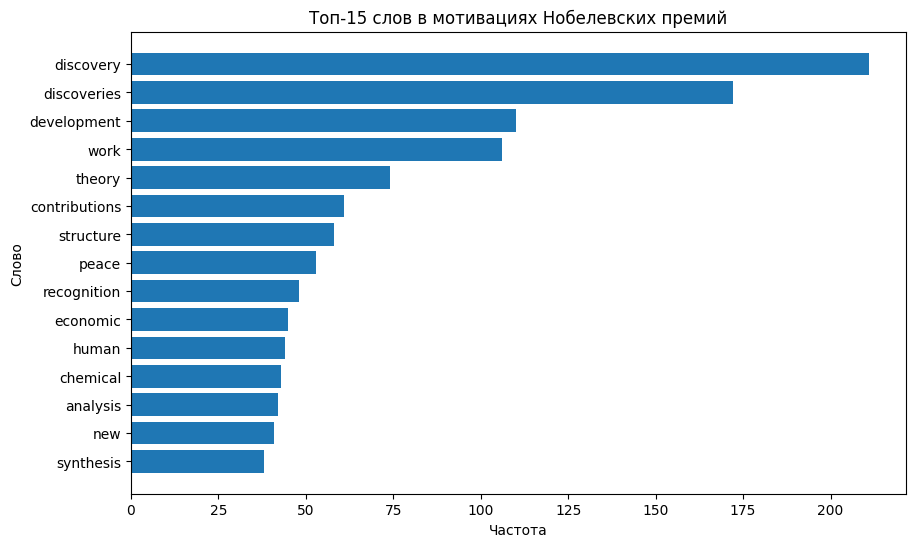

In [36]:
top_15 = top_n(filtered_counts, 15)

plot_words = []
plot_counts = []

for word, count in top_15:
    plot_words.append(word)
    plot_counts.append(count)

plt.figure(figsize=(10, 6))
plt.barh(plot_words[::-1], plot_counts[::-1])

plt.title('Топ-15 слов в мотивациях Нобелевских премий')
plt.xlabel('Частота')
plt.ylabel('Слово')
plt.show()

### Выводы лингвистического анализа

Всего было 1 036 текстов мотиваций вручения премий.

До удаления стоп-слов наиболее частыми оказались артикли, предлоги и союзы, которые не отражают специфику Нобелевской премии, поэтому мы исключили их из анализа вместе с другими общеупотребительными словами

После удаления стоп-слов наиболее частыми стали discovery (211), discoveries (172), development (110), work (106) и theory (74), то есть в мотивациях часто упоминаются открытия, разработки, научные работы и теории

При сравнении категорий можно выделить характерную для каждой из них лексику:

- Физика: discovery, development, quantum, theory
- Химия: development, discovery, chemistry, chemical
- Медицина: discoveries, discovery, cell, genetic
- Экономика: theory, economic, analysis
- Литература: human, life, poetry, poetic
- Мир:peace, efforts, international, rights

Наибольшее пересечение топ-10 слов наблюдается между физикой и химией (5 общих слов), у физики и медицины (4 общих слова) и у химии и медицины (3 общих слова)

При этом литература не пересекается с физикой, химией и медициной

В дальнейшем анализе было бы хорошо учесть формы слов (например discovery и discoveries), сейчас они подсчитываются отдельно